In [1]:

import os
import sys
from matplotlib import gridspec

# Add project root to path
sys.path.append(    os.path.abspath('../../'))
from BWM.ScriptsandFunctions.bwm_functions import *

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5


In [2]:
def plot_probe_trajectory(eid, directory_path='../Data2'):
    clusters_path = os.path.join(directory_path, eid, 'clusters.pkl')
    if not os.path.exists(clusters_path):
        print(f"File not found: {clusters_path}")
        return

    clusters = pd.read_pickle(clusters_path)
    xyz = clusters[['x', 'y', 'z']].values
    xyz = xyz[~np.isnan(xyz).any(axis=1)]
    
    if len(xyz) == 0:
        print("No valid XYZ coordinates found.")
        return

    # Map clusters to regions
    cluster_to_region = dict(zip(clusters.cluster_id, clusters.acronym))
    unique_regions = sorted(list(set(cluster_to_region.values())))
    
    print(f"Probe for EID {eid} passed through regions: {', '.join(unique_regions)}")
    return unique_regions 


In [3]:
# Data selection and plot execution


Total EIDs available: 459
Top EID: fcd49e34-f07b-441c-b2ac-cb8c462ec5ac with 3140 neurons
Selected EID 1e45d992-c356-40e1-9be1-a506d944896f at index 9
Figure saved to ../Figures/BWMSchematic_single_eid.jpg


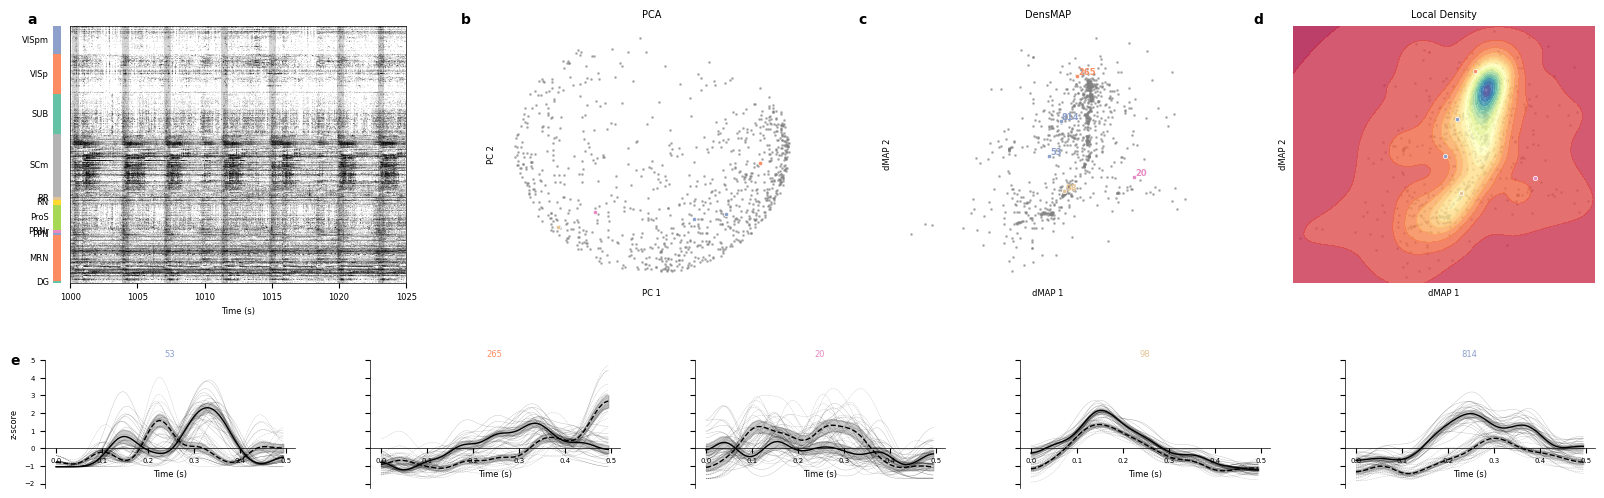

In [5]:
import os

data_path = '../Data2/'
# Get all available EIDs and their neuron counts
eid_counts = []
for d in os.listdir(data_path):
    eid_dir = os.path.join(data_path, d)
    if os.path.isdir(eid_dir):
        clusters_path = os.path.join(eid_dir, 'clusters.pkl')
        if os.path.exists(clusters_path):
            try:
                clusters = pd.read_pickle(clusters_path)
                eid_counts.append((d, len(clusters)))
            except Exception:
                continue

# Sort EIDs by neuron count in descending order
eid_counts.sort(key=lambda x: x[1], reverse=True)
all_eids = [x[0] for x in eid_counts]

print(f"Total EIDs available: {len(all_eids)}")
if all_eids:
    print(f"Top EID: {all_eids[0]} with {eid_counts[0][1]} neurons")

# Specify EID by index
eid_index = 9 # You can change this index to select a different EID
if eid_index < len(all_eids):
    eid1 = all_eids[eid_index]
    print(f"Selected EID {eid1} at index {eid_index}")
else:
    # Fallback to the original hardcoded EID if index is out of bounds or list is empty
    cp_eids = ['626126d5-eecf-4e9b-900e-ec29a17ece07']
    eid1 = cp_eids[0]
    print(f"Index {eid_index} out of bounds, selected fallback EID: {eid1}")

eid1 = "5c0c560e-9e1f-45e9-b66e-e4ee7855be84"

# Create a figure
fig = plt.figure(figsize=(20, 6))
gs_main = gridspec.GridSpec(1, 1, figure=fig)

plot_raster(eid1, start_time=1000, end_time=1025, fr_threshold=0, fig=fig, gs_sub=gs_main[0])

# Save the combined plot
os.makedirs('../Figures', exist_ok=True)
fig_path = os.path.join('../Figures', f'BWMSchematic_single_eid.jpg')
fig.savefig(fig_path, dpi=600, bbox_inches='tight')
print(f"Figure saved to {fig_path}")

plt.show()
